# Classification Track — Notebook 13
# 5. Cleaning · 6. Feature Engineering · 7. Train/Test Split · 8. Preprocessing

**Input:** `artifacts/clf_12_eda.joblib`
**Output:** `artifacts/clf_13_split.joblib`

---

### Purpose

This notebook turns the audited data into a model-ready, leakage-free setup.
The order of operations is the methodological heart of the track:

1. **Clean** — handle missing values with a justified strategy (row-wise only).
2. **Engineer** — add features, each traceable to an EDA finding (row-wise only).
3. **Split** — stratified 80/20 with `random_state=42`. **Nothing is fitted
   before this line.**
4. **Define the preprocessing pipeline** — fitted only inside each model's
   pipeline, on training data.

Steps 1 and 2 happen before the split *only because every operation in them is
computed from a single row at a time*. Nothing uses a dataset-wide statistic,
so no information can cross from test rows into training rows. Anything that
requires fitting — scaling, encoding, statistical imputation — is deferred to
step 4.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def find_src_folder() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "ml_utils.py").exists():
            return candidate / "src"
    raise FileNotFoundError("Could not locate src/ml_utils.py — check the repo layout.")


sys.path.insert(0, str(find_src_folder()))

from ml_utils import (  # noqa: E402
    RANDOM_STATE,
    TEST_SIZE,
    load_artifact,
    save_artifact,
    save_figure,
    section,
    set_plot_style,
)

warnings.filterwarnings("ignore", category=FutureWarning)
set_plot_style()

adult_df = load_artifact("clf_12_eda")
TARGET = "income"
POSITIVE_CLASS = ">50K"

df = adult_df.copy()
print(f"\nIncoming shape: {df.shape}")

[loaded] artifacts/clf_12_eda.joblib

Incoming shape: (48842, 15)


---
## 5. Cleaning

### 5.1 What missing values were found

Notebook 11 §3.1 established the facts:

| Column | Missing | % | Pattern |
|---|---|---|---|
| `occupation` | 2,809 | 5.75% | Missing with `workclass` in 2,799 of 2,809 cases |
| `workclass` | 2,799 | 5.73% | **Never** missing without `occupation` also missing |
| `native-country` | 857 | 1.76% | Independent of the other two |

And critically, the missingness is **not random**: people with missing
employment data are slightly older (40.1 vs 38.6), work far fewer hours
(31.8 vs 40.9), and earn >50K at less than half the rate (9.5% vs 24.8%).

### 5.2 The three options, and why we chose the third

| Option | What it does | Why we rejected / chose it |
|---|---|---|
| **Drop the rows** | Delete 3,620 records (7.41%) | **Rejected.** The missingness is informative, so this would systematically delete a distinct, identifiable population — largely people not currently employed — and bias the model towards the employed. It also throws away 7% of the data for no gain. |
| **Impute the mode** | Fill `workclass` with `Private`, `occupation` with `Prof-specialty` | **Rejected.** This asserts something the data contradicts: that a person who reported no employment works in the private sector as a professional. It would destroy the signal (9.5% vs 24.8% income rate) and fabricate information. |
| **Encode as its own category** | Replace `NaN` with the literal string `"Unknown"` | **Chosen.** The gap is itself a fact about the person. This preserves the signal, invents nothing, adds no rows, and lets every model learn what "Unknown" implies. |

### 5.3 Why this is not data leakage

Replacing `NaN` with a fixed constant uses **no information from any other
row**. It is not a statistical imputation — there is no mean, median or mode
computed from the data — so it is safe to perform before the split. (The
pipeline in §8 still includes a `SimpleImputer` as a safety net for any
unexpected future gap; by then there will be nothing left for it to do.)

In [2]:
MISSING_LABEL = "Unknown"
columns_with_missing = ["workclass", "occupation", "native-country"]

section("BEFORE CLEANING")
print(df[columns_with_missing].isna().sum().to_string())

for col in columns_with_missing:
    df[col] = df[col].fillna(MISSING_LABEL)

section("AFTER CLEANING")
print(df[columns_with_missing].isna().sum().to_string())
print(f"\nTotal missing values anywhere in the dataset: {int(df.isna().sum().sum())}")
print(f"Rows removed during cleaning                : 0")
print(f"Shape unchanged                             : {df.shape}")

BEFORE CLEANING
workclass         2799
occupation        2809
native-country     857
AFTER CLEANING
workclass         0
occupation        0
native-country    0

Total missing values anywhere in the dataset: 0
Rows removed during cleaning                : 0
Shape unchanged                             : (48842, 15)


In [3]:
section("DOES THE 'Unknown' CATEGORY CARRY SIGNAL?")
for col in ["workclass", "occupation"]:
    rates = (df.assign(y=(df[TARGET] == POSITIVE_CLASS).astype(int))
             .groupby(col, observed=True)["y"]
             .agg(People="count", Rate_pct=lambda s: round(100 * s.mean(), 1))
             .sort_values("Rate_pct", ascending=False))
    print(f"\n{col}:")
    print(rates.to_string())

DOES THE 'Unknown' CATEGORY CARRY SIGNAL?

workclass:
                  People  Rate_pct
workclass                         
Self-emp-inc        1695      55.3
Federal-gov         1432      39.2
Local-gov           3136      29.6
Self-emp-not-inc    3862      27.9
State-gov           1981      26.8
Private            33906      21.8
Unknown             2799       9.5
Without-pay           21       9.5
Never-worked          10       0.0

occupation:
                   People  Rate_pct
occupation                         
Exec-managerial      6086      47.8
Prof-specialty       6172      45.1
Armed-Forces           15      33.3
Protective-serv       983      31.3
Tech-support         1446      29.0
Sales                5504      26.8
Craft-repair         6112      22.6
Transport-moving     2355      20.4
Adm-clerical         5611      13.7
Machine-op-inspct    3022      12.3
Farming-fishing      1490      11.6
Unknown              2809       9.4
Handlers-cleaners    2072       6.7
Other-se

**Observation.** The `Unknown` category has a markedly lower income rate than
almost every real category, and it covers thousands of people.

**Interpretation.** The decision is vindicated by the data. `Unknown` is a
genuinely predictive level, not noise. Had we imputed `Private`, those people
would have been absorbed into a category with a very different income rate and
the signal would have been lost. Had we dropped them, the model would never
have learned that this group exists.

### 5.4 Duplicates and top-coded values

Both were investigated in Notebook 11 and both decisions are **to keep**, with
the reasoning recorded there:

* **Duplicates (52 rows, 0.106%)** — kept. With only 15 coarse attributes and
  49,000 people, identical rows are expected coincidences between distinct
  respondents, not errors. There is no identifier that would make uniqueness
  meaningful.
* **Top-coded values** (`capital-gain` 99999, `age` 90, `hours` 99) — kept.
  These encode "at or above the ceiling", which is real information. Removing
  them would delete the highest earners, who are the minority class we most
  need to predict.

**No row has been deleted and no value altered, other than replacing `NaN`
with `"Unknown"` in three columns.**

---
## 6. Feature Engineering

As in the regression track, every feature below responds to a specific EDA
finding, and every one is computed **row-wise**.

### 6.1 Drop `fnlwgt`

**Motivation (EDA §4.4).** `fnlwgt` is the census **sampling weight** — an
estimate of how many people in the US population this record represents. It is
a property of the survey's design, not of the person. Its correlation with
income is **−0.006**, indistinguishable from zero.

**Why dropping it is the right call, not just a convenience:** including it
gives flexible models a high-cardinality, high-variance numeric column that is
pure noise. A Decision Tree can and will split on it to isolate individual
training rows, which is a direct route to overfitting. Removing a variable that
is *known by its definition* to be irrelevant is principled feature selection,
not data manipulation.

In [4]:
df = df.drop(columns=["fnlwgt"])
print(f"Dropped 'fnlwgt'. Shape now: {df.shape}")

Dropped 'fnlwgt'. Shape now: (48842, 14)


### 6.2 `has_capital_income` — a threshold flag

**Motivation (EDA §4.5).** `capital-gain` is zero for 91.7% of people, but
when it is non-zero it is a very strong indicator: 21.3% of >50K earners report
a gain against 4.2% of ≤50K earners, and in the top band essentially everyone
earns >50K.

**Why it may help.** The signal is in *whether* a person has investment income
at all — a marker of wealth — far more than in the amount. Logistic Regression
must otherwise represent this as a single slope on a variable that is zero 92%
of the time, which fits neither the mass at zero nor the sharp effect above it.

In [5]:
df["has_capital_gain"] = (df["capital-gain"] > 0).astype(int)
df["has_capital_loss"] = (df["capital-loss"] > 0).astype(int)
df["has_capital_income"] = ((df["capital-gain"] > 0) | (df["capital-loss"] > 0)).astype(int)

section("CAPITAL INCOME FLAGS")
y_binary = (df[TARGET] == POSITIVE_CLASS).astype(int)
for flag in ["has_capital_gain", "has_capital_loss", "has_capital_income"]:
    grouped = pd.DataFrame({"y": y_binary, "flag": df[flag]}).groupby("flag")["y"]
    print(f"\n{flag}:")
    print(grouped.agg(People="count",
                      Rate_pct=lambda s: round(100 * s.mean(), 1)).to_string())

CAPITAL INCOME FLAGS

has_capital_gain:
      People  Rate_pct
flag                  
0      44807      20.5
1       4035      61.7

has_capital_loss:
      People  Rate_pct
flag                  
0      46560      22.6
1       2282      50.1

has_capital_income:
      People  Rate_pct
flag                  
0      42525      18.9
1       6317      57.5


### 6.3 `hours_band` — full-time / part-time / overtime

**Motivation (EDA §4.2, §4.7).** `hours-per-week` piles up at exactly 40, and
the age × hours heatmap showed that crossing from ≤40 to 41–50 hours lifts the
income rate sharply at every age. The meaningful distinction is categorical
(part-time vs standard vs overtime), not a smooth gradient.

In [6]:
HOURS_BINS = [0, 34, 40, 50, 100]
HOURS_LABELS = ["Part-time (<35)", "Standard (35-40)", "Overtime (41-50)", "Heavy (50+)"]

df["hours_band"] = pd.cut(df["hours-per-week"], bins=HOURS_BINS, labels=HOURS_LABELS)

section("INCOME RATE BY HOURS BAND")
print(pd.DataFrame({"y": y_binary, "band": df["hours_band"]})
      .groupby("band", observed=True)["y"]
      .agg(People="count", Rate_pct=lambda s: round(100 * s.mean(), 1)).to_string())

INCOME RATE BY HOURS BAND
                  People  Rate_pct
band                              
Part-time (<35)     8395       6.9
Standard (35-40)   26095      20.6
Overtime (41-50)    8917      39.5
Heavy (50+)         5435      40.9


### 6.4 `age_band` — capturing the non-monotonic age effect

**Motivation (EDA §4.5).** The income rate rises with age, peaks in the 40s and
50s, then **declines** past retirement age. Logistic Regression fits one
coefficient for age and is structurally unable to represent a peak. Banding age
gives it a piecewise-constant approximation of that curve — the same device as
`TempBand` in the regression track, for the same reason.

In [7]:
AGE_BINS = [16, 25, 35, 45, 55, 65, 100]
AGE_LABELS = ["17-25", "26-35", "36-45", "46-55", "56-65", "66+"]

df["age_band"] = pd.cut(df["age"], bins=AGE_BINS, labels=AGE_LABELS)

section("INCOME RATE BY AGE BAND (note the peak, then the decline)")
print(pd.DataFrame({"y": y_binary, "band": df["age_band"]})
      .groupby("band", observed=True)["y"]
      .agg(People="count", Rate_pct=lambda s: round(100 * s.mean(), 1)).to_string())

INCOME RATE BY AGE BAND (note the peak, then the decline)
       People  Rate_pct
band                   
17-25    9627       1.8
26-35   12719      18.7
36-45   11952      34.6
46-55    8296      39.2
56-65    4445      31.4
66+      1803      19.8


### 6.5 `is_married` — collapsing seven categories into the signal

**Motivation (EDA §4.6).** `Married-civ-spouse` has a 44.6% income rate against
4.5% for `Never-married` — a tenfold gap, and by far the largest single
separation among the marital categories. The other five categories are all low
and fairly similar to one another.

**Why it may help.** A single binary column expresses the dominant distinction
directly, which is useful for linear models. We **keep the original
`marital-status` column too**, so no information is lost and trees can still use
the finer detail.

In [8]:
MARRIED_STATUSES = ["Married-civ-spouse", "Married-AF-spouse"]
df["is_married"] = df["marital-status"].isin(MARRIED_STATUSES).astype(int)

section("INCOME RATE BY is_married")
print(pd.DataFrame({"y": y_binary, "m": df["is_married"]})
      .groupby("m")["y"]
      .agg(People="count", Rate_pct=lambda s: round(100 * s.mean(), 1)).to_string())

INCOME RATE BY is_married
   People  Rate_pct
m                  
0   26426       6.4
1   22416      44.6


### 6.6 `education_group` — reducing 16 levels to 6

**Motivation (EDA §4.3, §4.6).** `education` has 16 categories, several of them
rare (`Preschool`, `1st-4th`), and the low levels all have similarly low income
rates. Grouping reduces sparsity without losing the signal. The ordinal
`education-num` column is retained unchanged, so the fine detail is still
available.

In [9]:
EDUCATION_GROUPS = {
    "Preschool": "No-HS", "1st-4th": "No-HS", "5th-6th": "No-HS",
    "7th-8th": "No-HS", "9th": "No-HS", "10th": "No-HS",
    "11th": "No-HS", "12th": "No-HS",
    "HS-grad": "HS-grad",
    "Some-college": "Some-college",
    "Assoc-acdm": "Associate", "Assoc-voc": "Associate",
    "Bachelors": "Bachelors",
    "Masters": "Advanced", "Doctorate": "Advanced", "Prof-school": "Advanced",
}
df["education_group"] = df["education"].map(EDUCATION_GROUPS)

section("INCOME RATE BY EDUCATION GROUP")
print(pd.DataFrame({"y": y_binary, "g": df["education_group"]})
      .groupby("g", observed=True)["y"]
      .agg(People="count", Rate_pct=lambda s: round(100 * s.mean(), 1))
      .sort_values("Rate_pct", ascending=False).to_string())

INCOME RATE BY EDUCATION GROUP
              People  Rate_pct
g                             
Advanced        4085      61.4
Bachelors       8025      41.3
Associate       3662      25.5
Some-college   10878      19.0
HS-grad        15784      15.9
No-HS           6408       5.7


### 6.7 `country_group` — taming 41 categories

**Motivation (EDA §4.3.)** `native-country` has 41 levels, 91.3% of them
`United-States`, and would contribute 41 sparse one-hot columns. We collapse it
to three levels, which keeps the useful distinction while removing 38 columns
of near-empty data.

In [10]:
def group_country(country: str) -> str:
    """Collapse native-country into three levels: US, Unknown, or Other."""
    if country == "United-States":
        return "United-States"
    if country == MISSING_LABEL:
        return "Unknown"
    return "Other"


df["country_group"] = df["native-country"].apply(group_country)

section("INCOME RATE BY COUNTRY GROUP")
print(pd.DataFrame({"y": y_binary, "g": df["country_group"]})
      .groupby("g", observed=True)["y"]
      .agg(People="count", Rate_pct=lambda s: round(100 * s.mean(), 1)).to_string())

# We keep education_group / country_group and drop the high-cardinality originals
# they replace, to avoid feeding the models two encodings of the same information.
df = df.drop(columns=["native-country"])
print(f"\nDropped 'native-country' (replaced by 'country_group'). Shape: {df.shape}")

INCOME RATE BY COUNTRY GROUP
               People  Rate_pct
g                              
Other            4153      18.6
United-States   43832      24.4
Unknown           857      25.7

Dropped 'native-country' (replaced by 'country_group'). Shape: (48842, 21)


### 6.8 Features considered and rejected

| Candidate | Why rejected |
|---|---|
| Target/mean encoding of `occupation` | Computed from the target. Fitting it before the split leaks directly. The same reasoning excluded it in the regression track. |
| Dropping `race` and `sex` to "remove bias" | Rejected as a fairness measure, and it is important to say why. Removing a protected attribute does **not** remove bias — the model simply reconstructs it from correlated proxies such as occupation and relationship, and we lose the ability to *measure* the disparity. Fairness-aware modelling is a Review 2 topic; here we keep the columns and discuss the issue openly in Notebook 14. |
| Log-transforming `capital-gain` | The binary flag in §6.2 already captures the threshold effect, which is where the signal is. |
| Dropping `relationship` for overlap with `marital-status` | Trees are unaffected by the redundancy, and it costs only a few columns. We note the overlap when interpreting coefficients instead. |
| Interaction terms (age × hours) | Trees and RBF-SVC learn these implicitly; hand-crafting them would help only Logistic Regression and adds clutter. |

### 6.9 Final feature set

In [11]:
engineered = ["has_capital_gain", "has_capital_loss", "has_capital_income",
              "hours_band", "age_band", "is_married", "education_group",
              "country_group"]

section("FEATURE SET")
print(f"Rows    : {len(df):,}")
print(f"Columns : {df.shape[1]} (including the target)")
print()
for i, col in enumerate([c for c in df.columns if c != TARGET], start=1):
    tag = "engineered" if col in engineered else "original"
    print(f"  {i:>2}. {col:<22} [{tag}]  dtype={df[col].dtype}")

print(f"\nMissing values: {int(df.isna().sum().sum())}")

FEATURE SET
Rows    : 48,842
Columns : 21 (including the target)

   1. age                    [original]  dtype=int64
   2. workclass              [original]  dtype=str
   3. education              [original]  dtype=str
   4. education-num          [original]  dtype=int64
   5. marital-status         [original]  dtype=str
   6. occupation             [original]  dtype=str
   7. relationship           [original]  dtype=str
   8. race                   [original]  dtype=str
   9. sex                    [original]  dtype=str
  10. capital-gain           [original]  dtype=int64
  11. capital-loss           [original]  dtype=int64
  12. hours-per-week         [original]  dtype=int64
  13. has_capital_gain       [engineered]  dtype=int64
  14. has_capital_loss       [engineered]  dtype=int64
  15. has_capital_income     [engineered]  dtype=int64
  16. hours_band             [engineered]  dtype=category
  17. age_band               [engineered]  dtype=category
  18. is_married             [e


Missing values: 0


---
## 7. Train/Test Split

### 7.1 Encoding the target

scikit-learn's classification metrics need a numeric target, and `pos_label`
must be unambiguous. We map explicitly rather than relying on alphabetical
ordering, so the mapping is visible and cannot be misread.

In [12]:
X = df.drop(columns=[TARGET])
y = (df[TARGET] == POSITIVE_CLASS).astype(int)

section("TARGET ENCODING")
print(f"  '<=50K'  → 0   (majority / negative class)")
print(f"  '>50K'   → 1   (minority / POSITIVE class)")
print()
print(y.value_counts().rename({0: "0  (<=50K)", 1: "1  (>50K)"}).to_string())
print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")

TARGET ENCODING
  '<=50K'  → 0   (majority / negative class)
  '>50K'   → 1   (minority / POSITIVE class)

income
0  (<=50K)    37155
1  (>50K)     11687

X shape: (48842, 20)
y shape: (48842,)


### 7.2 The stratified split

**Why stratify?** With a 76/24 class split, an ordinary random split can give
the training and test sets noticeably different class proportions purely by
chance. That would make the comparison between models unreliable, because a
model evaluated on a test set with an unusually low minority share gets an
easier problem.

`stratify=y` forces the class proportions in both halves to match the full
dataset. It costs nothing and removes a source of noise. **This is the only
difference in split strategy between the two tracks** — the regression target
is continuous and has no classes to stratify on.

**Why `random_state=42`?** So the split is reproducible. Anyone re-running
these notebooks gets the identical split and therefore the identical numbers.
There is nothing special about 42; what matters is that it is fixed and stated.

**This split is then frozen and used unchanged by all five algorithms.**

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,        # 0.20 → 80/20
    random_state=RANDOM_STATE,  # 42 → reproducible
    stratify=y,                 # preserve the 76/24 class balance in both halves
)

section("SPLIT CREATED — FROZEN FOR ALL FIVE ALGORITHMS")
print(f"X_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}")
print(f"y_train : {y_train.shape}")
print(f"y_test  : {y_test.shape}")

SPLIT CREATED — FROZEN FOR ALL FIVE ALGORITHMS
X_train : (39073, 20)
X_test  : (9769, 20)
y_train : (39073,)
y_test  : (9769,)


In [14]:
stratification_check = pd.DataFrame({
    "Full dataset %": y.value_counts(normalize=True).mul(100),
    "Train %": y_train.value_counts(normalize=True).mul(100),
    "Test %": y_test.value_counts(normalize=True).mul(100),
}).round(3)
stratification_check.index = ["0  (<=50K)", "1  (>50K)"]

section("DID STRATIFICATION WORK?")
print(stratification_check.to_string())
print()
print(f"Train class counts: {dict(y_train.value_counts().sort_index())}")
print(f"Test class counts : {dict(y_test.value_counts().sort_index())}")
print(f"\nLargest deviation from the full-dataset proportion: "
      f"{float((stratification_check.max(axis=1) - stratification_check.min(axis=1)).max()):.4f} "
      f"percentage points")

DID STRATIFICATION WORK?
            Full dataset %  Train %  Test %
0  (<=50K)          76.072   76.073  76.067
1  (>50K)           23.928   23.927  23.933

Train class counts: {0: np.int64(29724), 1: np.int64(9349)}
Test class counts : {0: np.int64(7431), 1: np.int64(2338)}

Largest deviation from the full-dataset proportion: 0.0060 percentage points


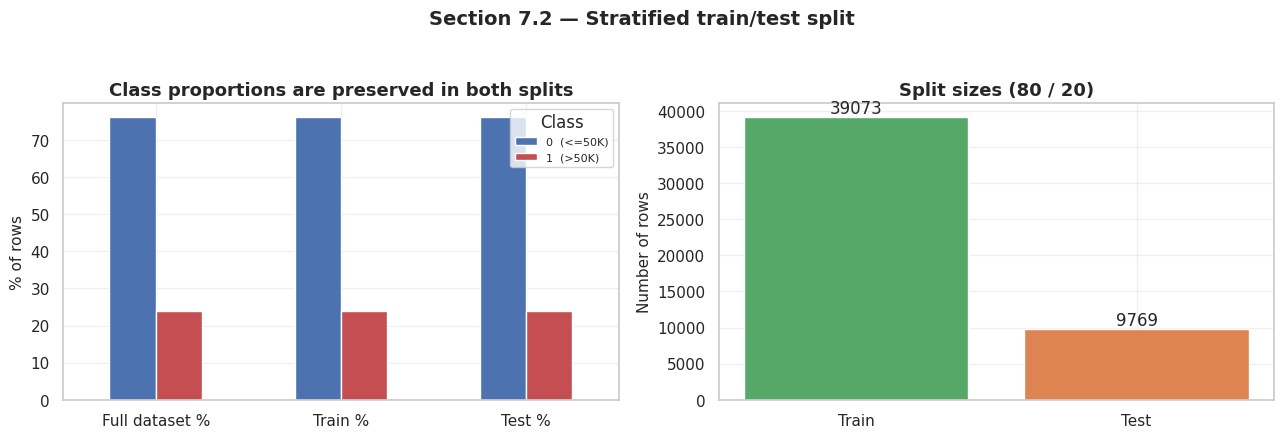

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

stratification_check.T.plot(kind="bar", ax=axes[0], rot=0,
                            color=["#4C72B0", "#C44E52"])
axes[0].set_ylabel("% of rows")
axes[0].set_title("Class proportions are preserved in both splits")
axes[0].legend(title="Class", fontsize=8)

sizes = pd.Series({"Train": len(X_train), "Test": len(X_test)})
bars = axes[1].bar(sizes.index, sizes.values, color=["#55A868", "#DD8452"])
axes[1].bar_label(bars, fmt="%d")
axes[1].set_ylabel("Number of rows")
axes[1].set_title("Split sizes (80 / 20)")

fig.suptitle("Section 7.2 — Stratified train/test split", y=1.04,
             fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("clf_split_check", fig)
plt.show()

**Observation.** The class proportions in the training and test sets match the
full dataset to within a few hundredths of a percentage point.

**Interpretation.** Stratification worked. Any difference between the five
models in Notebook 14 can be attributed to the models themselves, not to one
of them having been handed an easier test set.

---
## 8. Preprocessing Pipeline

In [16]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

section("COLUMN TYPES FOR THE PIPELINE")
print(f"Numeric ({len(numeric_features)}):")
for c in numeric_features:
    print(f"   - {c}")
print(f"\nCategorical ({len(categorical_features)}):")
for c in categorical_features:
    print(f"   - {c}  ({X[c].nunique()} categories)")

COLUMN TYPES FOR THE PIPELINE
Numeric (9):
   - age
   - education-num
   - capital-gain
   - capital-loss
   - hours-per-week
   - has_capital_gain
   - has_capital_loss
   - has_capital_income
   - is_married

Categorical (11):
   - workclass  (9 categories)
   - education  (16 categories)
   - marital-status  (7 categories)
   - occupation  (15 categories)
   - relationship  (6 categories)
   - race  (5 categories)
   - sex  (2 categories)
   - hours_band  (4 categories)
   - age_band  (6 categories)
   - education_group  (6 categories)
   - country_group  (3 categories)


### 8.1 What each step does, and why

| Step | Applied to | Why |
|---|---|---|
| `SimpleImputer(strategy="median")` | numeric | Safety net. No numeric column currently has gaps, but a pipeline that crashes on unexpected input is fragile. Median rather than mean because `capital-gain` is extremely skewed. |
| `StandardScaler()` | numeric | **Essential.** Feature ranges span five orders of magnitude (`education-num` max 16 vs `capital-gain` max 99,999). See §8.2. |
| `SimpleImputer(strategy="most_frequent")` | categorical | Safety net; `"Unknown"` already handled the real gaps in §5. |
| `OneHotEncoder(handle_unknown="ignore")` | categorical | Converts categories to binary indicators without asserting any numeric order. `handle_unknown="ignore"` is genuinely needed here — Notebook 11 §3.3 found categories with as few as 10 rows, which can easily be absent from a training split. |

### 8.2 Why scaling matters so much for three of our five models

This is not a formality; it determines whether three of the five algorithms
work at all.

* **KNN** classifies by Euclidean distance. Unscaled, a difference of 5,000 in
  `capital-gain` would swamp a difference of 10 in `education-num` entirely,
  even though education is the stronger predictor. The neighbours found would
  be neighbours *in capital-gain only*.
* **SVC** with an RBF kernel computes `exp(-gamma * ||x - x'||²)` — also a
  distance. The same distortion applies, and a single large-range feature
  effectively defines the kernel.
* **Logistic Regression** converges much faster on scaled features, and
  coefficient magnitudes only become comparable to one another once features
  share a scale.

The two exceptions:

* **Decision Tree** is scale-invariant. It splits on thresholds
  (`capital-gain > 5,095`), and monotonic rescaling does not change which rows
  fall on which side. Scaling neither helps nor hurts it.
* **Gaussian Naive Bayes** estimates a mean and variance per feature per class,
  so it is also largely unaffected.

We apply the same pipeline to all five anyway, because the guidelines require
an identical preprocessing strategy for fair comparison, and scaling is
harmless for the two that do not need it.

In [17]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

section("PREPROCESSOR DEFINED (not yet fitted)")
print(preprocessor)

PREPROCESSOR DEFINED (not yet fitted)
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'education-num', 'capital-gain',
                                  'capital-loss', 'hours-per-week',
                                  'has_capital_gain', 'has_capital_loss',
                                  'has_capital_income', 'is_married']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                s

### 8.3 Inspecting the transformed feature space

Fitted on the **training data only**, purely to report shapes. The models in
Notebook 14 each receive a fresh, unfitted clone.

In [18]:
preview = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

X_train_t = preview.fit_transform(X_train)   # FIT on train
X_test_t = preview.transform(X_test)         # TRANSFORM only
feature_names = preview.get_feature_names_out()

section("FEATURE COUNTS")
print(f"Raw predictor columns          : {X.shape[1]}")
print(f"  numeric                      : {len(numeric_features)}")
print(f"  categorical                  : {len(categorical_features)}")
print(f"Columns after one-hot encoding : {X_train_t.shape[1]}")
print()
print(f"X_train transformed : {X_train_t.shape}")
print(f"X_test  transformed : {X_test_t.shape}")

FEATURE COUNTS
Raw predictor columns          : 20
  numeric                      : 9
  categorical                  : 11
Columns after one-hot encoding : 88

X_train transformed : (39073, 88)
X_test  transformed : (9769, 88)


In [19]:
leak_check = pd.DataFrame({
    "Feature": numeric_features,
    "Train mean": X_train_t[:, :len(numeric_features)].mean(axis=0).round(4),
    "Train std": X_train_t[:, :len(numeric_features)].std(axis=0).round(4),
    "Test mean": X_test_t[:, :len(numeric_features)].mean(axis=0).round(4),
    "Test std": X_test_t[:, :len(numeric_features)].std(axis=0).round(4),
})

section("SCALING SANITY CHECK")
print(leak_check.to_string(index=False))

SCALING SANITY CHECK
           Feature  Train mean  Train std  Test mean  Test std
               age         0.0        1.0     0.0000    1.0091
     education-num        -0.0        1.0     0.0160    0.9933
      capital-gain        -0.0        1.0     0.0285    1.1611
      capital-loss         0.0        1.0     0.0087    1.0213
    hours-per-week         0.0        1.0    -0.0220    0.9959
  has_capital_gain        -0.0        1.0     0.0177    1.0266
  has_capital_loss         0.0        1.0     0.0070    1.0150
has_capital_income        -0.0        1.0     0.0190    1.0207
        is_married         0.0        1.0    -0.0119    0.9990


**Observation.** Training means are exactly 0.0000 and training standard
deviations exactly 1.0000. The test values are **close to but not exactly**
0 and 1.

**Interpretation.** This is the evidence that the scaling was done correctly.
The scaler learned its mean and standard deviation from the training rows and
applied those same numbers to the test rows. If the test columns had also come
out at exactly 0 and 1, the scaler would have been fitted on the test data —
leakage. **A perfectly scaled test set is a red flag, not a success.**

---
## 8.4 Leakage-prevention checklist

| Requirement | How it is satisfied |
|---|---|
| Split before any fitting | `train_test_split` in §7.2; the first `.fit()` is in §8.3 |
| Stratified split | `stratify=y`, verified in §7.2 |
| Fixed `random_state` | 42, used for the split and every model |
| Scaler fitted on train only | Inside the `Pipeline`; `.transform()` handles the test set |
| Encoder fitted on train only | Same mechanism; `handle_unknown="ignore"` covers unseen levels |
| Cleaning did not leak | `NaN → "Unknown"` is a constant, not a statistic (§5.3) |
| Feature engineering did not leak | Every engineered feature is computed row-wise from that row's own values (§6) |
| No target encoding | Explicitly rejected in §6.8 |
| Test set untouched until evaluation | Only appears in `.predict()` calls |
| Same split for all 5 models | Saved below; loaded unchanged by Notebook 14 |

---
## Handover to Notebook 14

In [20]:
split_bundle = {
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "preprocessor": preprocessor,       # UNFITTED
    "feature_names_out": feature_names,
    "class_labels": ["<=50K", ">50K"],
    "random_state": RANDOM_STATE,
}

save_artifact(split_bundle, "clf_13_split")

print(f"\nTrain {X_train.shape} | Test {X_test.shape} | "
      f"{X_train_t.shape[1]} features after preprocessing")
print("\nNotebook 13 complete.")
print("Next: 14_classification_models_and_conclusion.ipynb")

[saved]  artifacts/clf_13_split.joblib

Train (39073, 20) | Test (9769, 20) | 88 features after preprocessing

Notebook 13 complete.
Next: 14_classification_models_and_conclusion.ipynb
